# TP5 – CNN Applications & Grad-CAM (Keras)
In this TP, you will:
- Load and use a pre-trained ResNet50 model
- Predict the class of a custom image
- Visualize class activation maps (Grad-CAM) to interpret the result

Libraries: TensorFlow / Keras / Matplotlib / OpenCV

## Import libraries

In [ ]:
# Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image


## Load and preprocess your image

4783815/4783815 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


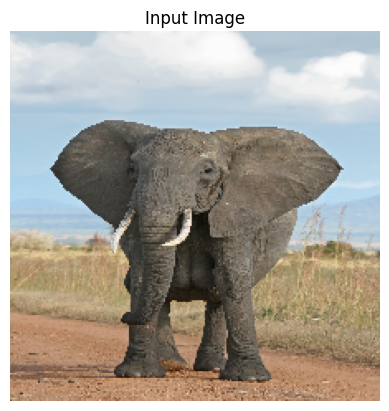

In [ ]:
# Load and preprocess your image
img_path = tf.keras.utils.get_file('elephant.jpg',
    'https://upload.wikimedia.org/wikipedia/commons/3/37/African_Bush_Elephant.jpg')

img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

plt.imshow(img)
plt.title("Input Image")
plt.axis('off')
plt.show()

## Load the pre-trained ResNet50 model

In [ ]:
# 🔍 Load the pre-trained ResNet50 model
model = ResNet50(weights='imagenet')
preds = model.predict(x)
print("Predicted:", decode_predictions(preds, top=3)[0])

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Predicted: [('n02504458', 'African_elephant', np.float32(0.885714)), ('n01871265', 'tusker', np.float32(0.06552603)), ('n02504013', 'Indian_elephant', np.float32(0.03665784))]


# Grad-CAM Implementation

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


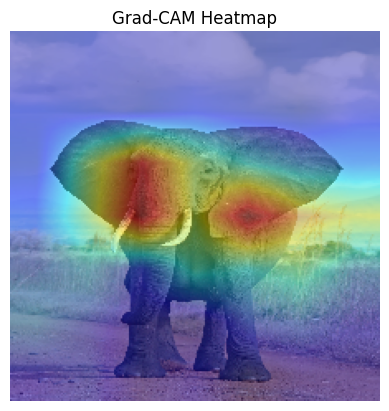

In [ ]:
# Grad-CAM Implementation
grad_model = tf.keras.models.Model(
    inputs=[model.inputs],
    outputs=[model.get_layer('conv5_block3_out').output, model.output]
)

with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(x)
    class_idx = tf.argmax(predictions[0])
    class_output = predictions[:, class_idx]

grads = tape.gradient(class_output, conv_outputs)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

conv_outputs = conv_outputs[0]
heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap)
heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
heatmap = heatmap.numpy()

# Overlay heatmap on original image
img = cv2.imread(img_path)
img = cv2.resize(img, (224, 224))
heatmap = cv2.resize(heatmap, (224, 224))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img, 0.6, heatmap, 0.4, 0)

plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM Heatmap")
plt.axis('off')
plt.show()